**Task 1 — Data Import & Setup**

**Data Import & Setup: Import CSV using Pandas.**

upload the file from the computer to colab .

In [2]:
from google.colab import files
uploaded = files.upload()

Saving social_media_engagement_5000.csv to social_media_engagement_5000 (1).csv


**Converting the csv file to panda dataframe**


In [3]:
import pandas as pd
df=pd.read_csv("social_media_engagement_5000.csv")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         4850 non-null   object 


**Convert date columns to datetime**

In [5]:
df["posted_at"]=pd.to_datetime(
                    df["posted_at"],
                    errors="coerce"
                    )


/tmp/ipykernel_1078/4138066781.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["posted_at"]=pd.to_datetime(


In [6]:
df["posted_at"].dtype

dtype('<M8[ns]')

**Task 2 — Data Cleaning**

In [8]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


Here we are checking for missing values in the column

In [9]:
df.isnull().sum()

,0
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


we are removing the duplictae values

In [10]:
df.duplicated().sum()

np.int64(0)

importing numpy and performing basic operations  

In [11]:
import numpy as np
likes_array=np.array(df["likes"].dropna())

In [12]:
print("Average likes = ",np.mean(likes_array))
print("Maximum likes = ",np.max(likes_array))
print("Minimum likes = ",np.min(likes_array))
print("Total likes = ",np.sum(likes_array))

Average likes =  10107.043711340206
Maximum likes =  19998.0
Minimum likes =  10.0
Total likes =  49019162.0


here we are changeing the data type of age from flot to int

In [13]:
df["age"] = pd.to_numeric(df["age"], errors="coerce").astype("Int64")

handeling the missing values by putting thr median value of each column to it

we are using fillna()  to this

In [14]:
num_cols=["age","likes","comments","shares"]
for col in num_cols :
       df[col] = df[col].fillna(df[col].median())


checking if the inconsistency have been handeled

In [15]:
print(df[num_cols].isnull().sum())

age         0
likes       0
comments    0
shares      0
dtype: int64


In [16]:
df.isnull().sum()

,0
user_id,0
age,0
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,0
comments,0
shares,0


handeling the missing values by add ing the mode value of the column

the mode of the age and sentiment column is calcutated and added

In [17]:
gender_mode=df["gender"].mode()[0]
print(gender_mode)

Male


In [18]:
df["gender"]=df['gender'].fillna(gender_mode)

In [19]:
sentiment_mode=df["sentiment"].mode()[0]
print(sentiment_mode)

positive


In [20]:
df["sentiment"]=df["sentiment"].fillna(df["sentiment"].mode()[0])

In [21]:
df.isnull().sum()

,0
user_id,0
age,0
gender,0
country,0
post_id,0
post_type,0
post_category,0
likes,0
comments,0
shares,0


**Standardize categories**

.str.strip() :Removes unwanted spaces.
.str.title() :make the first letter of each category capital.

In [82]:
df["gender"] = df["gender"].str.strip().str.title()

print(df["gender"].unique())

['Female' 'Male' 'Other']


**Correct unrealistic values in likes, comments, shares**

identify unusually low or high values.

In [25]:
print(df["likes"].min())
print(df["likes"].max())

print(df["comments"].min())
print(df["comments"].max())

print(df["shares"].min())
print(df["shares"].max())

10.0
19998.0
0.0
2999.0
0.0
1999.0


In [26]:
print(df["hashtags"].head())

0    #foodie #travel #love
1                 #fitness
2                  #foodie
3      #music #foodie #fun
4                  #travel
Name: hashtags, dtype: object


creating a variable called hastag_count to count the number of # in each

In [27]:
df["hashtag_count"] = df["hashtags"].str.count("#")

In [28]:
print(df[["hashtags", "hashtag_count"]].head(10))

                  hashtags  hashtag_count
0    #foodie #travel #love              3
1                 #fitness              1
2                  #foodie              1
3      #music #foodie #fun              3
4                  #travel              1
5                 #fitness              1
6                   #music              1
7  #travel #music #fitness              3
8     #music #fun #fitness              3
9         #lifestyle #love              2


**Task 3 — Data Exploration using Pandas**

**View dataset structure using head(), tail(), shape, and columns.**

head(): to displays the first 5 rows of the dataset.
df.tail() : Displays the last 5 rows of the dataset.
df.shape: Returns the number of rows and columns as a tuple.
df.columns: Displays all column names in the dataset.

In [29]:
print(df.head())


   user_id  age  gender country  post_id post_type post_category    likes  \
0    25795   43  Female  Brazil   496713     image       fitness   7011.0   
1    10860   33    Male  Brazil   157326      reel          food  11750.0   
2    86820   32  Female      UK   109864      text          food   4862.0   
3    64886   51   Other  France   848877      text       fitness   5350.0   
4    16265   34   Other      UK   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count  posted_at  \
0     354.0  1157.0            5726             44650 2022-12-17   
1    2606.0  1807.0            5947             80216 2023-06-02   
2     344.0   955.0            6946             44858 2023-05-07   
3    1083.0  1049.0             229             70455 2023-02-12   
4    2735.0  1300.0            4798              6019 2023-05-23   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      mobile  negat

In [30]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63,Female,USA,273595,text,travel,13487.0,1497.0,167.0,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54,Other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


In [31]:
df.shape

(5000, 20)

In [32]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='object')

**Check data types and info with info() and dtypes.**


In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   Int64         
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

In [34]:
df.dtypes

,0
user_id,int64
age,Int64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


**Generate summary statistics using describe().**

Calculates statistical values for numerical columns.
* count
* mean
* min
* 25%
* 50%
* 75%
* max
* std



In [35]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.0,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.4404,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.0,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.0,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.0,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.0,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.0,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


df.describe(include="object"):
Selects columns with the object data type, such as gender etc.

In [36]:
df.describe(include="object")

,gender,country,post_type,post_category,device_type,sentiment,hashtags
count,5000,5000,5000,5000,5000,5000,5000
unique,3,10,4,8,3,3,761
top,Male,India,reel,fitness,mobile,positive,#tech
freq,1849,535,1283,675,1684,2513,201


**Analyze categorical distributions using value_counts(), unique(), and
nunique().**

* value_counts() : Counts how many times each unique value appears in a column.
* unique() : Displays all distinct values in a column without repeating duplicates.
* nunique() : Counts the total number of distinct values in a column.


In [37]:
df["post_type"].value_counts()

,count
post_type,
reel,1283
image,1247
text,1245
video,1225


In [38]:
df["post_type"].unique()

array(['image', 'reel', 'text', 'video'], dtype=object)

In [39]:
df["country"].nunique()

10

**Create a correlation matrix for numeric fields.**

It is to find the relation between the columns and how they are corelated.

In [40]:
df[["likes", "comments", "shares", "watch_time_sec"]].corr()

,likes,comments,shares,watch_time_sec
likes,1.000000,-0.018421,0.004712,0.008710
comments,-0.018421,1.000000,0.006142,-0.016351
shares,0.004712,0.006142,1.000000,0.014658
watch_time_sec,0.008710,-0.016351,0.014658,1.000000


**Use groupby() to summarize metrics (e.g., avg likes by post type, impressions
by country).**

In [41]:
df.groupby("post_type")["likes"].mean()

,likes
post_type,
image,10104.865277
reel,10037.802416
text,10100.148193
video,10188.600000


In [42]:
df.groupby("post_type")["comments"].mean()

,comments
post_type,
image,1525.235766
reel,1504.187062
text,1499.106024
video,1479.160000


**Task 4 — Data Wrangling**

Create new fields such as engagement_score, log-transformed metrics
(optional), and hashtag_count.

here we are creatinga new column engagement_score which is a sum of likes comments and share


In [43]:
df["engagement_score"] = (
    df["likes"] + df["comments"] + df["shares"]
)

print(df[["likes", "comments", "shares", "engagement_score"]].head())

     likes  comments  shares  engagement_score
0   7011.0     354.0  1157.0            8522.0
1  11750.0    2606.0  1807.0           16163.0
2   4862.0     344.0   955.0            6161.0
3   5350.0    1083.0  1049.0            7482.0
4  12682.0    2735.0  1300.0           16717.0


displaying the 10 rows of the newly created  column engagement_score

In [44]:
df[["likes", "comments", "shares", "engagement_score"]].head(10)

,likes,comments,shares,engagement_score
0,7011.0,354.0,1157.0,8522.0
1,11750.0,2606.0,1807.0,16163.0
2,4862.0,344.0,955.0,6161.0
3,5350.0,1083.0,1049.0,7482.0
4,12682.0,2735.0,1300.0,16717.0
5,12535.0,1790.0,99.0,14424.0
6,11703.0,2276.0,1465.0,15444.0
7,9611.0,146.0,424.0,10181.0
8,10105.5,2379.0,1897.0,14381.5
9,14106.0,2480.0,1053.0,17639.0


**Perform groupby summaries by post_type, country, and sentiment**



In [45]:
df.groupby("post_type")["engagement_score"].mean()

,engagement_score
post_type,
image,12649.390537
reel,12524.031567
text,12613.243775
video,12664.594286


In [46]:
df.groupby("country")["engagement_score"].mean()

,engagement_score
country,
Australia,12809.621704
Brazil,12385.983135
Canada,12605.894737
France,12903.384073
Germany,12635.664286
India,12492.701869
Japan,12578.648305
UAE,12757.777336
UK,12384.374239


In [47]:
df.groupby("sentiment")["engagement_score"].mean()

,engagement_score
sentiment,
negative,12731.498958
neutral,12448.163720
positive,12665.799443


In [48]:
columns = [
    "likes",
    "comments",
    "shares",
    "watch_time_sec",
    "engagement_rate",
    "follower_count"
]

df[columns].mean()

,0
likes,10106.997400
comments,1502.039800
shares,1002.910600
watch_time_sec,4014.503200
engagement_rate,0.964356
follower_count,393698.224800


In [49]:
df[columns].median()

,0
likes,10105.500000
comments,1497.000000
shares,1012.000000
watch_time_sec,4034.500000
engagement_rate,0.253896
follower_count,388982.000000


In [50]:
df[columns].mode().iloc[0]

,0
likes,10105.500000
comments,1497.000000
shares,1012.000000
watch_time_sec,916.000000
engagement_rate,0.006363
follower_count,497502.000000


In [51]:
df[columns].std()

,0
likes,5702.293017
comments,856.393312
shares,570.855200
watch_time_sec,2308.096459
engagement_rate,5.318029
follower_count,230927.884535


In [52]:
df[columns].var()

,0
likes,3.251615e+07
comments,7.334095e+05
shares,3.258757e+05
watch_time_sec,5.327309e+06
engagement_rate,2.828143e+01
follower_count,5.332769e+10


In [53]:
df[columns].quantile([0.25, 0.50, 0.75])

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
0.25,5235.0,792.00,511.0,2017.75,0.145781,194480.00
0.50,10105.5,1497.00,1012.0,4034.50,0.253896,388982.00
0.75,14959.0,2235.25,1483.0,6020.25,0.504794,589744.25


**Task 6 — Data Visualization**

**Scatter: likes vs impressions**
* Here we are creating a graph to  visualize the relationship between the number of impressions and likes received by each social media post.



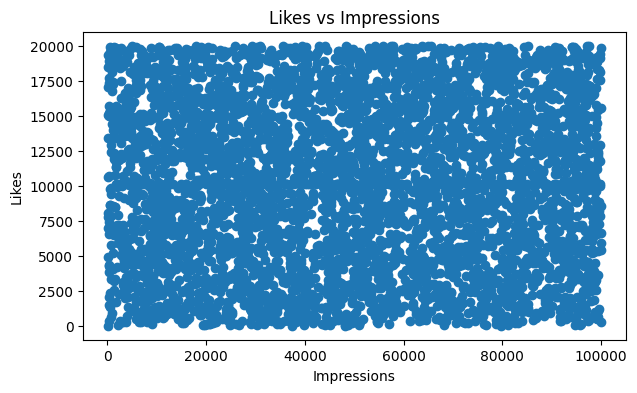

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,4 ))

plt.scatter(df["impression_count"], df["likes"])

plt.xlabel("Impressions")
plt.ylabel("Likes")
plt.title("Likes vs Impressions")

plt.show()

here we are calculating the average engagement score of posts published on each dates to make the analysis easy .we are creating a variable as daily_engagement, and the calculated value is stored here .


In [55]:
daily_engagement = df.groupby(
    df["posted_at"].dt.date
)["engagement_score"].mean()

print(daily_engagement.head())

posted_at
2022-01-01    12018.333333
2022-01-02    12058.125000
2022-01-03    11628.800000
2022-01-04    10576.666667
2022-01-05    12982.200000
Name: engagement_score, dtype: float64


**Line: daily engagement trend**

the daily_engagement value is taken and the line graph is calculated .

date is taken as the x axis

average engagement score as y axis .

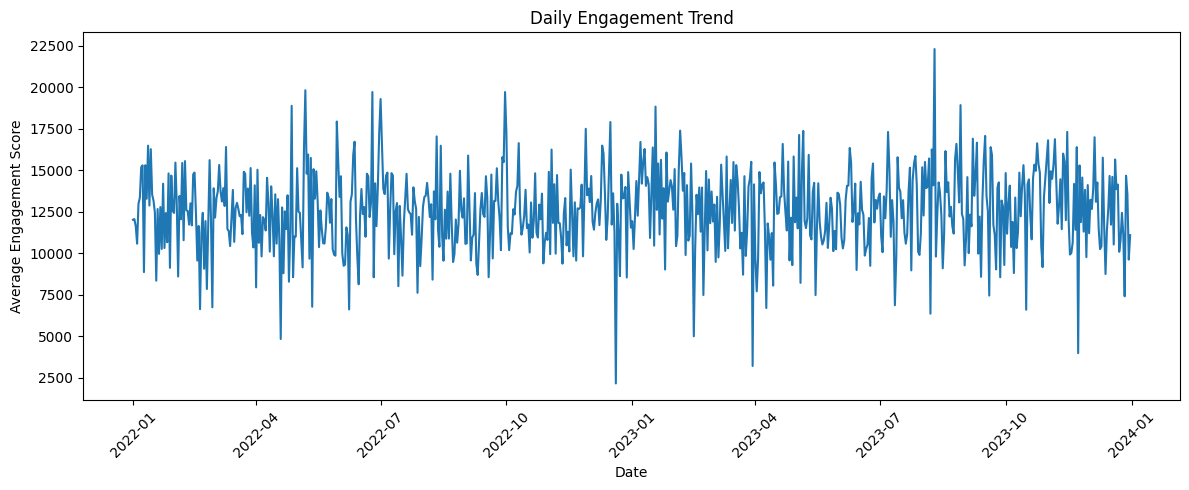

In [56]:
plt.figure(figsize=(12, 5))

plt.plot(daily_engagement.index, daily_engagement.values)

plt.xlabel("Date")
plt.ylabel("Average Engagement Score")
plt.title("Daily Engagement Trend")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Here we are calculating the count of no. of post in each cactegory to plot the bar graph.

In [57]:
category_counts = df["post_category"].value_counts()
print(category_counts)

post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64


**Bar: posts by category**

Here we are creating a bar graph on the count of each category.

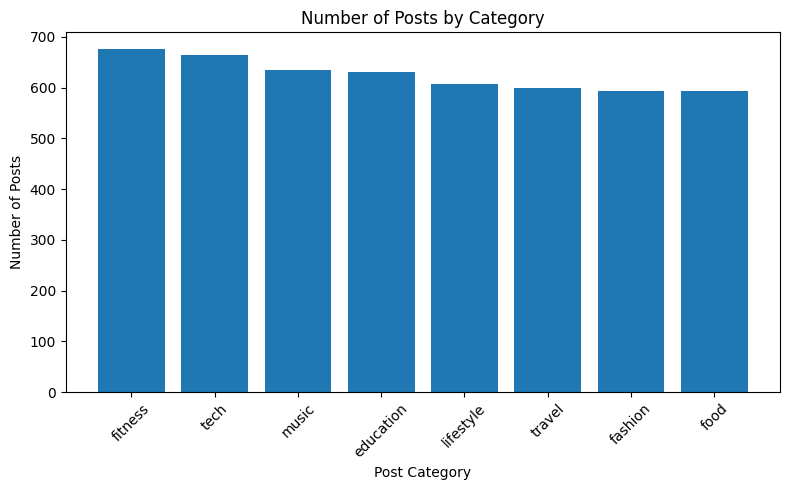

In [58]:
plt.figure(figsize=(8, 5))

plt.bar(category_counts.index, category_counts.values)

plt.xlabel("Post Category")
plt.ylabel("Number of Posts")
plt.title("Number of Posts by Category")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Here we are taking the count of each unique values within gender column and store it in gender_counts

In [59]:
gender_counts = df["gender"].value_counts()

print(gender_counts)

gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64


**Pie: gender distribution**

here we are creating a pie chart ti display the gender column

autopct="%1.1f%%"  : is used to diplay the percentage value on the chart

the title is given as gender distribution .

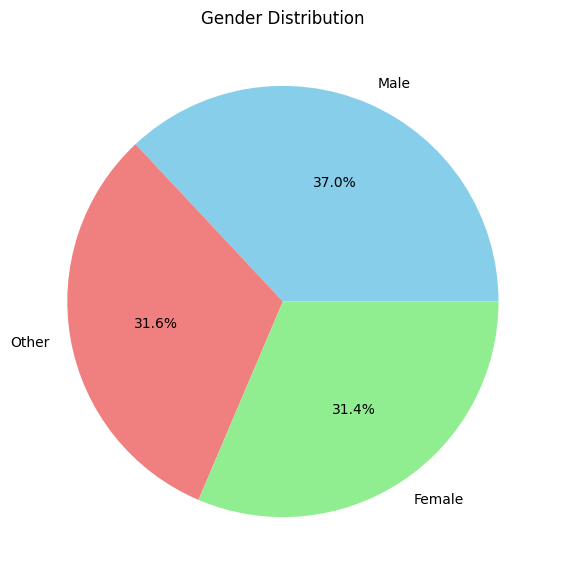

In [60]:
plt.figure(figsize=(7, 7))

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    colors=["skyblue", "lightcoral", "lightgreen"]
)

plt.title("Gender Distribution")
plt.show()

**Histogram: age**

Here we are creating a histogram

age in x axis.

number if users in y axis .

title as age distribution

we are creating this graph to shows how many users fall into different age ranges.

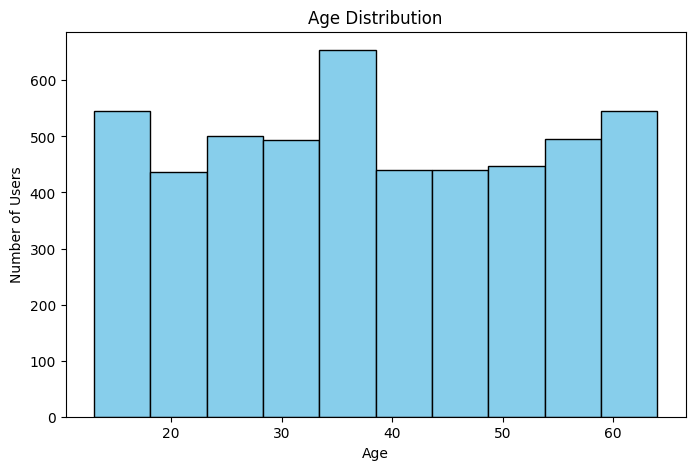

In [61]:
plt.figure(figsize=(8, 5))

plt.hist(df["age"], bins=10, edgecolor="black", color="skyblue")

plt.xlabel("Age")
plt.ylabel("Number of Users")
plt.title("Age Distribution")

plt.show()

**Box: engagement rate**

here we are createing a box plot to visualize the distribution of engagement rates

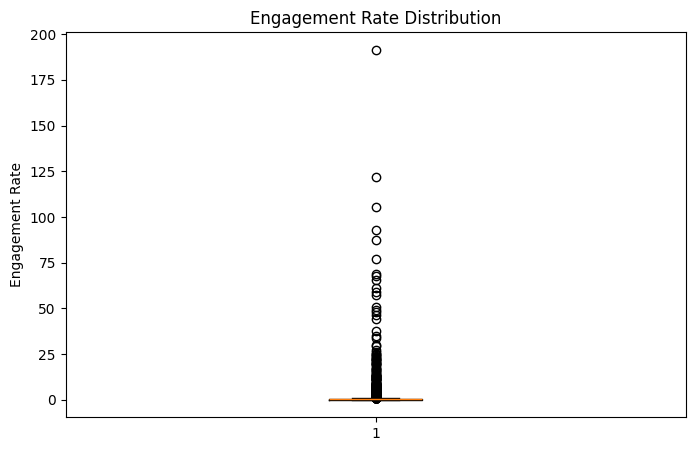

In [62]:
plt.figure(figsize=(8, 5))

plt.boxplot(df["engagement_rate"])

plt.ylabel("Engagement Rate")
plt.title("Engagement Rate Distribution")

plt.show()

**Seaborn**

**Count plot: post type**

we are importing the Seaborn library for statistical data visualization.

Createing a count plot that automatically counts the occurrences of each categories.

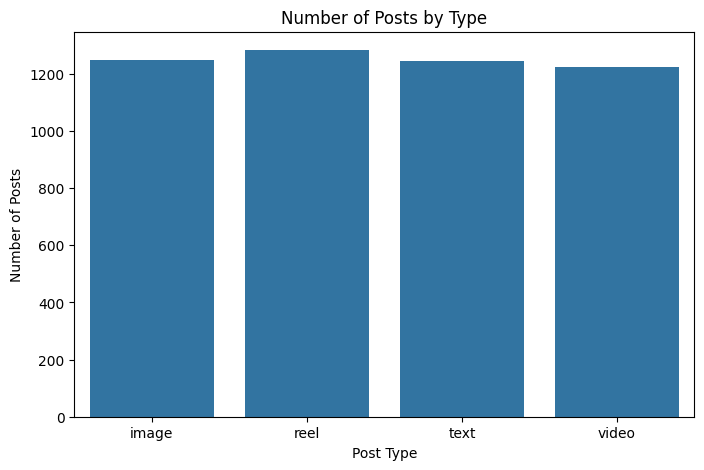

In [63]:
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="post_type")

plt.xlabel("Post Type")
plt.ylabel("Number of Posts")
plt.title("Number of Posts by Type")

plt.show()

**Heatmap: correlation matrix.**

 we are calculating the correlation between numerical columns
 * likes
 * comments
 * shares
 * watch_time_sec
 * impression_count
 * engagement_rate
 * follower_count

In [64]:
corr = df[
    ["likes", "comments", "shares", "watch_time_sec",
     "impression_count", "engagement_rate", "follower_count"]
].corr()

print(corr)

                     likes  comments    shares  watch_time_sec  \
likes             1.000000 -0.018421  0.004712        0.008710   
comments         -0.018421  1.000000  0.006142       -0.016351   
shares            0.004712  0.006142  1.000000        0.014658   
watch_time_sec    0.008710 -0.016351  0.014658        1.000000   
impression_count  0.007952 -0.009395 -0.005204       -0.004335   
engagement_rate   0.093520  0.000051  0.021724       -0.001148   
follower_count   -0.022982 -0.011733 -0.010783        0.002761   

                  impression_count  engagement_rate  follower_count  
likes                     0.007952         0.093520       -0.022982  
comments                 -0.009395         0.000051       -0.011733  
shares                   -0.005204         0.021724       -0.010783  
watch_time_sec           -0.004335        -0.001148        0.002761  
impression_count          1.000000        -0.232226       -0.015513  
engagement_rate          -0.232226         1.000000

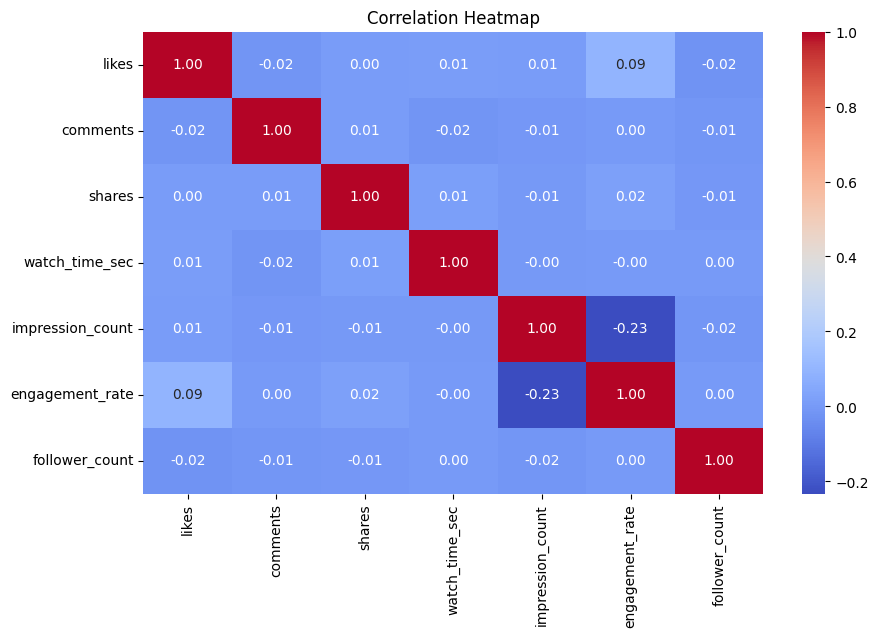

In [65]:
plt.figure(figsize=(10, 6))

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

**Plotly**

In [66]:
import plotly.express as px

In [67]:
avg_likes = df.groupby("post_type", as_index=False)["likes"].mean()

fig = px.bar(
    avg_likes,
    x="post_type",
    y="likes",
    title="Average Likes by Post Type",
    labels={
        "post_type": "Post Type",
        "likes": "Average Likes"
    }
)

fig.show()

In [68]:
fig = px.scatter(
    df,
    x="impression_count",
    y="likes",
    color="post_type",
    title="Likes vs Impressions by Post Type",
    labels={
        "impression_count": "Impressions",
        "likes": "Likes"
    }
)

fig.show()

**Final Insights should Include following analysis**

**● Content Performance**

**Which post types have the highest engagement?**

In [69]:
df.groupby("post_type")["engagement_score"].mean().sort_values(ascending=False)

,engagement_score
post_type,
video,12664.594286
image,12649.390537
text,12613.243775
reel,12524.031567


**Best-performing content category?**

In [70]:
df.groupby("post_category")["engagement_score"].mean().sort_values(ascending=False)

,engagement_score
post_category,
music,12788.549606
food,12739.200675
tech,12686.490226
travel,12650.559167
lifestyle,12639.539539
education,12578.270206
fitness,12457.791852
fashion,12356.420875


**Which countries have highest avg engagement rate?**


In [71]:
df.groupby("country")["engagement_rate"].mean().sort_values(ascending=False)

,engagement_rate
country,
Brazil,1.540704
Australia,1.324339
France,1.146402
UAE,1.112352
Canada,0.916659
UK,0.850966
Japan,0.769623
Germany,0.759000
India,0.655005


**How age affects engagement**

In [72]:
df.groupby("age")["engagement_score"].mean().sort_values(ascending=False)

,engagement_score
age,
49,14162.194444
17,14156.450000
33,13796.268817
14,13469.014706
36,13468.524752
39,13462.858025
50,13418.241379
31,13279.258427
38,13245.217803


**Behavioral Insights**

**Performance difference for verified accounts**


In [73]:
df.groupby("is_verified")["engagement_score"].mean()

,engagement_score
is_verified,
False,12644.311822
True,12309.280538


**Best time of day for impressions**

In [74]:
df["post_hour"] = df["posted_at"].dt.hour

In [75]:
df.groupby("post_hour")["impression_count"].mean().sort_values(ascending=False)

,impression_count
post_hour,
0,50013.7328


In [76]:
df["post_hour"].value_counts().sort_index()

,count
post_hour,
0,5000


**Device type impact on watch time**

In [77]:
df.groupby("device_type")["watch_time_sec"].mean().sort_values(ascending=False)

,watch_time_sec
device_type,
mobile,4087.830760
tablet,3979.736429
desktop,3974.792521


**Sentiment Analysis**

**Which sentiment performs best**

In [78]:
df.groupby("sentiment")["engagement_score"].mean().sort_values(ascending=False)

,engagement_score
sentiment,
negative,12731.498958
positive,12665.799443
neutral,12448.163720


**Behavior of negative/neutral sentiment posts**

In [79]:
df.groupby("sentiment")[["likes", "comments", "shares"]].mean()

,likes,comments,shares
sentiment,,,
negative,10208.096875,1516.094792,1007.307292
neutral,9923.194499,1528.404060,996.565160
positive,10180.062077,1480.650617,1005.086749
